# Target trials emulation across stroke severity and treatment

## Introduction

### Aims

This notebook uses target trial emulation on routinely collected stroke registry data (SAMSS) to estimate the effect of thrombolysis (IVT) and thrombectomy (MT) on patient outcomes. Treatment is broken down by:

* **Stroke severity:** NIHSS bands 1–5, 6–10, 11–15, 16–20 and 21–42.
* **Treatment timing:** early (≤ 270 minutes from onset) or late (> 270 minutes).
* **Treatment combination:** IVT alone, MT alone, or IVT + MT.
* **Perfusion imaging:** for late treatment, with or without perfusion imaging.

Each combination is defined in `trial_groups.csv` and analysed as its own emulated trial. The aim is to compare outcomes across these treatment strategies on a consistent footing.

### Methods

1. **Population.** Ischaemic stroke (infarction) patients with a recorded discharge mRS. Patients recorded as receiving thrombolysis after thrombectomy are excluded.
2. **Treatment groups.** Patients are classed as having early or late IVT and MT using `CUTOFF` (270 minutes from onset). Patients with treatment but no recorded time are classed as late. Each trial group's *treated* arm is the patients in its NIHSS band with exactly its treatment pattern. For groups with late treatment, the perfusion-imaging pattern must also match. Early-only groups include patients with or without perfusion imaging.
3. **Controls.** The *untreated* arm is patients in the same NIHSS band who received neither IVT nor MT.
4. **Matching.** Each treated patient is matched 1:1, without replacement, to an untreated patient with identical values of `MATCHING_FEATURES`: prior disability, NIHSS band, age, anticoagulant use for AF, and any AF diagnosis. Treated patients without a match are dropped, and the percentage matched is reported for each group. Untreated patients may serve as controls in more than one group.
5. **Outcomes.**
   * Good outcome: discharge mRS ≤ `MRS_TARGET` or no worse than pre-stroke (binary).
   * Discharge mRS (continuous).
   * Discharge destination (categorical).
   * Length of stay (continuous).
   * In-hospital death (binary).
6. **Analysis.** Because the data are matched pairs, paired methods are used:
   * Binary outcomes: McNemar's test, risk difference with 95% CI and matched-pair odds ratio.
   * Continuous outcomes: Wilcoxon signed-rank test (paired t-test also reported) and mean difference with 95% CI.
   * Categorical outcomes: Stuart–Maxwell test.

   Holm-adjusted p-values account for testing across trial groups within each outcome. Results estimate the effect of treatment in the treated.
7. **Outputs.** For each outcome, a statistics table (CSV) and a chart (PNG) are saved to `output/` using the `prefix` set at the top of the notebook.

### Limitations

Matching is on a small set of baseline features. Untreated patients may differ from treated patients in ways not captured, for example arrival time, contraindications, or other reasons for not being treated. Estimates may therefore be affected by residual confounding and should be read as associations rather than causal effects.

In [1]:
import numpy as np
import pandas as pd

In [2]:
prefix = "all_ischaemic_stroke_target_trials"
MRS_TARGET = 2
CUTOFF = 270

## Define fields

In [3]:
DESCRIPTIVE_FEATURES = [
    'prior_disability',
    'stroke_severity',
    'age',
    'congestive_heart_failure',
    'hypertension',
    'diabetes',
    'afib_anticoagulant',
    'any_afib_diagnosis',
]

TREATMENT_FEATURES = [
    'perfusion_imaging_used',
    'onset_to_thrombolysis_time',
    'onset_to_thrombectomy_time',
    'arrival_to_thrombolysis_time',
    'arrival_to_thrombectomy_time',
    'early_ivt',
    'early_mt',
    'late_ivt',
    'late_mt',
]

MATCHING_FEATURES = [
    'prior_disability',
    'stroke_severity_band',
    'age',
    'afib_anticoagulant',
    'any_afib_diagnosis',
]

OUTCOME_FEATURES = [
    'outcome_target',
    'discharge_disability',
    'discharge_destination',
    'death',
    'length_of_stay',
]

ALL_FEATURES = list(set(
    DESCRIPTIVE_FEATURES + TREATMENT_FEATURES + MATCHING_FEATURES + OUTCOME_FEATURES))


## Load and filter data

In [4]:
data = pd.read_csv("../data/sam3/cleaned_data.csv", low_memory=False)

# Calculate onset_to_scan
data["onset_to_scan_time"] = data["onset_to_arrival_time"] - data["arrival_to_scan_time"]

print(f"Initial data shape: {data.shape}")

# Remove rows with missing discharge disability
data = data.dropna(subset=["discharge_disability"])

# Keep only infarction cases
data = data[data["infarction"] == 1]

thrombolysis_after_thrombectomy = (
    data["onset_to_thrombolysis_time"] > data["onset_to_thrombectomy_time"]
)
data = data[~thrombolysis_after_thrombectomy]

# add 'early_ivt' if 'thrombolysosis' is 1 and 'onset_to_thrombolysis_time' <= CUTOFF
data["early_ivt"] = (
    (data["thrombolysis"] == 1) & (data["onset_to_thrombolysis_time"] <= CUTOFF)
).astype(int)

# Add 'late_ivt' if 'thrombolysosis' is 1 and 'onset_to_thrombolysis_time' is empty or > CUTOFF
data["late_ivt"] = (
    (data["thrombolysis"] == 1)
    & (
        (data["onset_to_thrombolysis_time"].isna())
        | (data["onset_to_thrombolysis_time"] > CUTOFF)
    )
).astype(int)

# Add 'early_mt' if 'thrombectomy' is 1 and 'onset_to_thrombectomy_time' <= CUTOFF
data["early_mt"] = (
    (data["thrombectomy"] == 1) & (data["onset_to_thrombectomy_time"] <= CUTOFF)
).astype(int)

# Add 'late_mt' if 'thrombectomy' is 1 and 'onset_to_thrombectomy_time' is empty or > CUTOFF
data["late_mt"] = (
    (data["thrombectomy"] == 1)
    & (
        (data["onset_to_thrombectomy_time"].isna())
        | (data["onset_to_thrombectomy_time"] > CUTOFF)
    )
).astype(int)


# Add stroke_severity_band, using the NIHSS bands defined in trial_groups.csv
# (e.g. 1-5, 6-10, 11-15, 16-20, 21-42). NIHSS outside all bands (e.g. 0) -> NaN.
severity_bands = (
    pd.read_csv("./trial_groups.csv")[["NIHSS Min", "NIHSS Max"]]
    .drop_duplicates()
    .sort_values("NIHSS Min")
    .reset_index(drop=True)
)
# Bands must be contiguous, with no gaps or overlaps
assert (
    severity_bands["NIHSS Min"].iloc[1:].values
    == severity_bands["NIHSS Max"].iloc[:-1].values + 1
).all(), "NIHSS bands in trial_groups.csv are not contiguous"

severity_bins = [severity_bands["NIHSS Min"].iloc[0] - 1] + severity_bands["NIHSS Max"].tolist()
severity_labels = [f"{lo}-{hi}" for lo, hi in severity_bands.itertuples(index=False)]

data["stroke_severity_band"] = pd.cut(
    pd.to_numeric(data["stroke_severity"], errors="coerce"),
    bins=severity_bins,
    labels=severity_labels,
    right=True,  # (0, 5] -> "1-5", (5, 10] -> "6-10", ...
)

# Add outcome variable: mRS <= MRS_TARGET or return to pre-stroke mRS
data["outcome_target"] = (
    (data["discharge_disability"] <= MRS_TARGET)
    | (data["discharge_disability"] <= data["prior_disability"])).astype(int)

# Select features 
data = data[ALL_FEATURES]


print(f"Final data shape: {data.shape}")

Initial data shape: (452863, 74)
Final data shape: (384334, 23)


In [5]:
# Import treatment groups
treatment_groups_df = pd.read_csv("./trial_groups.csv", low_memory=False)
display(treatment_groups_df)

,Group ID,Group name,NIHSS Min,NIHSS Max,IVT<= 270,IVT>270,MT<=270,MT>270,Perfusion imaging
0,1,NIHSS 1-5: IVT early,1,5,1,0,0,0,0
1,2,NIHSS 1-5: IVT late,1,5,0,1,0,0,0
2,3,NIHSS 1-5: IVT late (perfusion),1,5,0,1,0,0,1
3,4,NIHSS 6-10: IVT early,6,10,1,0,0,0,0
4,5,NIHSS 6-10: IVT late,6,10,0,1,0,0,0
5,6,NIHSS 6-10: IVT late (perfusion),6,10,0,1,0,0,1
6,7,NIHSS 11-15: IVT early,11,15,1,0,0,0,0
7,8,NIHSS 11-15: IVT late,11,15,0,1,0,0,0
8,9,NIHSS 11-15: IVT late (perfusion),11,15,0,1,0,0,1
9,10,NIHSS 11-15: MT early,11,15,0,0,1,0,0


## Match treated and untreated patients

For each treatment group:

* **Treated** patients are in the group's NIHSS band and have exactly the group's treatment pattern (early/late IVT, early/late MT).
* **Untreated** patients are in the same NIHSS band and had neither IVT nor MT.

Each treated patient is matched 1:1, without replacement, to an untreated patient with identical `MATCHING_FEATURES`. Treated patients without a match (including those missing any matching feature) are dropped, and the percentage of treated patients matched is recorded for each group. The same untreated patient may be used as a control in different groups.

In [6]:
RANDOM_SEED = 42

# Treatment columns in trial_groups.csv -> treatment flags in data
TREATMENT_FLAG_COLUMNS = {
    "IVT<= 270": "early_ivt",
    "IVT>270": "late_ivt",
    "MT<=270": "early_mt",
    "MT>270": "late_mt",
}
TREATMENT_FLAGS = list(TREATMENT_FLAG_COLUMNS.values())

# Columns defining each group's treated pattern: treatment flags + perfusion imaging.
# Perfusion imaging is not a treatment, so it does not restrict the untreated pool.
GROUP_PATTERN_COLUMNS = {**TREATMENT_FLAG_COLUMNS, "Perfusion imaging": "perfusion_imaging_used"}

# Untreated: no thrombolysis or thrombectomy at any time
untreated = (data[TREATMENT_FLAGS] == 0).all(axis=1)

# Patients missing any matching feature cannot be exactly matched
complete_matching_data = data[MATCHING_FEATURES].notna().all(axis=1)


def exact_match(treated, controls, features, rng):
    """1:1 exact matching without replacement.

    Within each combination of `features`, treated and untreated patients are
    put in random order and paired off. Treated patients left over when a
    combination has too few untreated patients are unmatched.

    Returns a DataFrame of (treated_id, control_id) index pairs.
    """
    def ranked(df, id_name):
        df = df[features].iloc[rng.permutation(len(df))].copy()
        df["_rank"] = df.groupby(features, observed=True).cumcount()
        return df.rename_axis(id_name).reset_index()

    pairs = ranked(treated, "treated_id").merge(
        ranked(controls, "control_id"), on=features + ["_rank"], how="inner"
    )
    return pairs[["treated_id", "control_id"]]


rng = np.random.default_rng(RANDOM_SEED)
matched_groups = []
summary_rows = []

for _, group in treatment_groups_df.iterrows():
    summary = {"group_id": group["Group ID"], "group_name": group["Group name"], "note": ""}

    band = f"{group['NIHSS Min']}-{group['NIHSS Max']}"
    in_band = data["stroke_severity_band"] == band

    # Treated: in band, with exactly this group's treatment and perfusion pattern.
    # Perfusion imaging only distinguishes late-treatment groups; early-only groups
    # include patients with or without perfusion imaging.
    has_late_treatment = group["IVT>270"] == 1 or group["MT>270"] == 1
    is_treated = in_band.copy()
    for sheet_col, data_col in GROUP_PATTERN_COLUMNS.items():
        if sheet_col == "Perfusion imaging" and not has_late_treatment:
            continue
        is_treated &= data[data_col] == group[sheet_col]

    treated = data[is_treated]
    controls = data[in_band & untreated & complete_matching_data]
    pairs = exact_match(
        data[is_treated & complete_matching_data], controls, MATCHING_FEATURES, rng
    )

    n_treated = len(treated)
    summary.update({
        "n_treated": n_treated,
        "n_treated_missing_matching_data": int((~complete_matching_data[is_treated]).sum()),
        "n_untreated_pool": len(controls),
        "n_matched": len(pairs),
        "pct_treated_matched": round(100 * len(pairs) / n_treated, 1) if n_treated else np.nan,
    })
    summary_rows.append(summary)

    # Build matched treated + untreated rows, linked by pair_id
    pair_id = np.arange(len(pairs))
    group_matched = pd.concat([
        data.loc[pairs["treated_id"]].assign(treated=1, pair_id=pair_id),
        data.loc[pairs["control_id"]].assign(treated=0, pair_id=pair_id),
    ]).rename_axis("patient_id").reset_index()
    group_matched.insert(0, "group_id", group["Group ID"])
    group_matched.insert(1, "group_name", group["Group name"])
    matched_groups.append(group_matched)

matched_data = pd.concat(matched_groups, ignore_index=True)
match_summary = pd.DataFrame(summary_rows).set_index("group_id")

print(f"Matched data shape: {matched_data.shape}")
display(match_summary)

Matched data shape: (113354, 28)


,group_name,note,n_treated,n_treated_missing_matching_data,n_untreated_pool,n_matched,pct_treated_matched
group_id,,,,,,,
1,NIHSS 1-5: IVT early,,12954,0,186476,12954,100.0
2,NIHSS 1-5: IVT late,,1441,0,186476,1440,99.9
3,NIHSS 1-5: IVT late (perfusion),,0,0,186476,0,NaN
4,NIHSS 6-10: IVT early,,13620,0,55383,13618,100.0
5,NIHSS 6-10: IVT late,,1478,0,55383,1478,100.0
6,NIHSS 6-10: IVT late (perfusion),,0,0,55383,0,NaN
7,NIHSS 11-15: IVT early,,6289,0,20318,6277,99.8
8,NIHSS 11-15: IVT late,,643,0,20318,643,100.0
9,NIHSS 11-15: IVT late (perfusion),,0,0,20318,0,NaN


## Target trials

Each treatment group is analysed as its own emulated trial, comparing matched treated patients with their matched untreated controls. This estimates the effect of treatment in the treated. Pairs where either patient is missing the outcome are dropped. Because the data are matched pairs, paired methods are used:

* **Binary outcomes:** percentage in each arm, difference in percentage points with 95% CI, matched-pair odds ratio (discordant pairs) with 95% CI, McNemar's test.
* **Continuous outcomes:** mean, SD, median and IQR in each arm, mean difference with 95% CI, Wilcoxon signed-rank test (`p_value`) and paired t-test (`p_value_paired_t`).
* **Categorical outcomes:** percentage in each category in each arm, Stuart-Maxwell test of marginal homogeneity.

Many groups are tested for each outcome, so Holm-adjusted p-values (`p_value_holm`, adjusted across groups within each outcome) are also reported. Charts mark groups with Holm-adjusted p < 0.05. Each outcome's statistics table (CSV) and chart (PNG) are saved to `output/`.

In [7]:
import os

import matplotlib.pyplot as plt
from scipy import stats as sps
from statsmodels.stats.contingency_tables import SquareTable, mcnemar
from statsmodels.stats.multitest import multipletests

OUTPUT_DIR = "./output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Category values treated as missing in categorical outcomes
MISSING_CATEGORIES = ["missing"]

# Chart colours (reference data-viz palette, light mode)
TREATED_COLOUR = "#2a78d6"
UNTREATED_COLOUR = "#eb6834"
CATEGORY_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID_COLOUR = "#e4e3df"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID_COLOUR,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "text.color": TEXT_PRIMARY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "font.size": 9,
})


def paired_outcome(group_data, outcome):
    """One row per matched pair, with the outcome for the treated and untreated
    patient. Pairs where either patient is missing the outcome are dropped."""
    wide = group_data.pivot(index="pair_id", columns="treated", values=outcome)
    wide = wide.rename(columns={1: "treated", 0: "untreated"})[["treated", "untreated"]]
    return wide.dropna()


def binary_stats(wide):
    """Paired comparison of a binary outcome: difference in proportions with
    95% CI, matched-pair odds ratio and McNemar's test."""
    t = wide["treated"].astype(int)
    u = wide["untreated"].astype(int)
    n = len(wide)
    both = int(((t == 1) & (u == 1)).sum())
    treated_only = int(((t == 1) & (u == 0)).sum())
    untreated_only = int(((t == 0) & (u == 1)).sum())
    neither = n - both - treated_only - untreated_only

    diff = t - u
    rd = diff.mean() if n else np.nan
    se = diff.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan

    # Matched-pair odds ratio uses discordant pairs only
    if treated_only > 0 and untreated_only > 0:
        matched_or = treated_only / untreated_only
        log_se = np.sqrt(1 / treated_only + 1 / untreated_only)
        or_low, or_high = matched_or * np.exp(-1.96 * log_se), matched_or * np.exp(1.96 * log_se)
    else:
        matched_or = or_low = or_high = np.nan

    try:
        discordant = treated_only + untreated_only
        p = mcnemar([[both, treated_only], [untreated_only, neither]], exact=discordant < 25).pvalue
    except Exception:
        p = np.nan

    return {
        "n_pairs": n,
        "treated_events": int(t.sum()),
        "treated_pct": 100 * t.mean() if n else np.nan,
        "untreated_events": int(u.sum()),
        "untreated_pct": 100 * u.mean() if n else np.nan,
        "difference": 100 * rd,
        "ci_low": 100 * (rd - 1.96 * se),
        "ci_high": 100 * (rd + 1.96 * se),
        "matched_odds_ratio": matched_or,
        "or_ci_low": or_low,
        "or_ci_high": or_high,
        "test": "McNemar",
        "p_value": p,
    }


def continuous_stats(wide):
    """Paired comparison of a continuous outcome: mean difference with 95% CI,
    Wilcoxon signed-rank test (primary p-value) and paired t-test."""
    t = wide["treated"].astype(float)
    u = wide["untreated"].astype(float)
    n = len(wide)
    diff = t - u
    md = diff.mean() if n else np.nan

    if n > 1:
        half_width = sps.t.ppf(0.975, n - 1) * diff.std(ddof=1) / np.sqrt(n)
        ci_low, ci_high = md - half_width, md + half_width
        p_t = sps.ttest_rel(t, u).pvalue
    else:
        ci_low = ci_high = p_t = np.nan
    try:
        p_w = sps.wilcoxon(t, u).pvalue
    except ValueError:
        p_w = np.nan

    return {
        "n_pairs": n,
        "treated_mean": t.mean(),
        "treated_sd": t.std(),
        "treated_median": t.median(),
        "treated_q1": t.quantile(0.25),
        "treated_q3": t.quantile(0.75),
        "untreated_mean": u.mean(),
        "untreated_sd": u.std(),
        "untreated_median": u.median(),
        "untreated_q1": u.quantile(0.25),
        "untreated_q3": u.quantile(0.75),
        "difference": md,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "test": "Wilcoxon signed-rank",
        "p_value": p_w,
        "p_value_paired_t": p_t,
    }


def categorical_stats(wide, categories):
    """Paired comparison of a categorical outcome: percentage in each category
    and the Stuart-Maxwell test of marginal homogeneity."""
    n = len(wide)
    row = {"n_pairs": n}
    for cat in categories:
        row[f"treated_pct_{cat}"] = 100 * (wide["treated"] == cat).mean() if n else np.nan
    for cat in categories:
        row[f"untreated_pct_{cat}"] = 100 * (wide["untreated"] == cat).mean() if n else np.nan

    table = pd.crosstab(wide["treated"], wide["untreated"]).reindex(
        index=categories, columns=categories, fill_value=0
    )
    used = (table.sum(axis=0) + table.sum(axis=1)) > 0
    table = table.loc[used, used]
    try:
        p = SquareTable(table.to_numpy(), shift_zeros=False).homogeneity().pvalue
    except Exception:
        p = np.nan
    row["test"] = "Stuart-Maxwell"
    row["p_value"] = p
    return row


def format_p(p):
    if pd.isna(p):
        return "p = n/a"
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def pretty_category(cat):
    return cat.replace("_", " ").replace("ssnap", "SSNAP").replace("esd", "ESD").capitalize()


def plot_paired_results(results, treated_col, untreated_col, value_label, diff_label, title, path):
    """Two panels sharing the group axis: each arm's value, and the treated minus
    untreated difference with 95% CI (filled = Holm-adjusted p < 0.05)."""
    res = results[results["n_pairs"] > 0].iloc[::-1]  # first group at the top
    y = np.arange(len(res))
    sig = (res["p_value_holm"] < 0.05).to_numpy()

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(13, 0.3 * len(res) + 2), sharey=True, layout="constrained"
    )

    # Panel 1: value in each arm
    ax1.hlines(y, res[untreated_col], res[treated_col], color=GRID_COLOUR, lw=2, zorder=1)
    ax1.scatter(res[untreated_col], y, s=40, color=UNTREATED_COLOUR, edgecolor=SURFACE,
                linewidth=1.5, zorder=2, label="Untreated (matched)")
    ax1.scatter(res[treated_col], y, s=40, color=TREATED_COLOUR, edgecolor=SURFACE,
                linewidth=1.5, zorder=3, label="Treated")
    ax1.set_yticks(y, res["group_name"])
    ax1.set_xlabel(value_label)
    ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)

    # Panel 2: difference with 95% CI
    ax2.axvline(0, color=TEXT_SECONDARY, lw=1, zorder=1)
    ax2.hlines(y, res["ci_low"], res["ci_high"], color=TREATED_COLOUR, lw=2, zorder=2)
    ax2.scatter(res["difference"][sig], y[sig], s=40, color=TREATED_COLOUR, edgecolor=SURFACE,
                linewidth=1.5, zorder=3, label="Holm-adjusted p < 0.05")
    ax2.scatter(res["difference"][~sig], y[~sig], s=40, facecolor=SURFACE, edgecolor=TREATED_COLOUR,
                linewidth=1.5, zorder=3, label="Not significant")
    ax2.set_xlabel(diff_label)
    ax2.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)

    for ax in (ax1, ax2):
        ax.grid(axis="x", color=GRID_COLOUR, lw=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(left=False)

    fig.suptitle(title, x=0.01, ha="left", fontsize=12, color=TEXT_PRIMARY)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


def plot_categorical_results(results, categories, title, path):
    """100% stacked bars of the outcome categories for the treated and untreated
    arm of each group, with the Holm-adjusted Stuart-Maxwell p-value."""
    res = results[results["n_pairs"] > 0]
    y, labels, values = [], [], []
    for g, (_, r) in enumerate(res.iterrows()):
        for k, arm in enumerate(["treated", "untreated"]):
            y.append(-(3 * g + k))
            labels.append(f"{r['group_name']}   Treated" if arm == "treated" else "Untreated")
            values.append([r[f"{arm}_pct_{cat}"] for cat in categories])
    y = np.array(y)
    values = np.array(values)

    fig, ax = plt.subplots(figsize=(13, 0.22 * len(y) + 0.12 * len(res) + 2), layout="constrained")
    left = np.zeros(len(y))
    for j, cat in enumerate(categories):
        ax.barh(y, values[:, j], left=left, height=0.85, color=CATEGORY_COLOURS[j],
                edgecolor=SURFACE, linewidth=1, label=pretty_category(cat))
        left += values[:, j]

    for g, (_, r) in enumerate(res.iterrows()):
        ax.text(101, -(3 * g + 0.5), format_p(r["p_value_holm"]), va="center", ha="left",
                color=TEXT_SECONDARY, clip_on=False)

    ax.set_yticks(y, labels)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Patients (%)   [p-values: Stuart-Maxwell, Holm-adjusted]")
    ax.tick_params(left=False)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=len(categories), frameon=False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, color=TEXT_PRIMARY)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


def analyse_outcome(outcome, outcome_type, title, value_label=None, diff_label=None, category_order=None):
    """Run the target trial for one outcome in every treatment group.

    outcome_type is "binary", "continuous" or "categorical". Saves a statistics
    table (CSV) and a chart (PNG) to OUTPUT_DIR and returns the statistics table.
    """
    outcome_data = matched_data[["group_id", "group_name", "pair_id", "treated", outcome]].copy()

    categories = None
    if outcome_type == "categorical":
        is_missing = outcome_data[outcome].isin(MISSING_CATEGORIES)
        outcome_data[outcome] = outcome_data[outcome].where(~is_missing)
        present = outcome_data[outcome].dropna().unique().tolist()
        categories = [c for c in (category_order or []) if c in present]
        categories += sorted(c for c in present if c not in categories)

    rows = []
    for (group_id, group_name), group_data in outcome_data.groupby(["group_id", "group_name"]):
        wide = paired_outcome(group_data, outcome)
        if outcome_type == "binary":
            group_stats = binary_stats(wide)
        elif outcome_type == "continuous":
            group_stats = continuous_stats(wide)
        elif outcome_type == "categorical":
            group_stats = categorical_stats(wide, categories)
        else:
            raise ValueError(f"Unknown outcome type: {outcome_type}")
        rows.append({"group_id": group_id, "group_name": group_name, **group_stats})

    results = pd.DataFrame(rows).set_index("group_id")

    # Holm adjustment across treatment groups, within this outcome
    results["p_value_holm"] = np.nan
    has_p = results["p_value"].notna()
    if has_p.any():
        results.loc[has_p, "p_value_holm"] = multipletests(results.loc[has_p, "p_value"], method="holm")[1]

    table_path = f"{OUTPUT_DIR}/{prefix}_{outcome}_stats.csv"
    chart_path = f"{OUTPUT_DIR}/{prefix}_{outcome}_chart.png"
    results.to_csv(table_path)

    if outcome_type == "categorical":
        plot_categorical_results(results, categories, title, chart_path)
    else:
        stat = "pct" if outcome_type == "binary" else "mean"
        if diff_label is None:
            diff_label = ("Difference, treated − untreated (percentage points)" if outcome_type == "binary"
                          else "Mean difference, treated − untreated")
        plot_paired_results(results, f"treated_{stat}", f"untreated_{stat}", value_label, diff_label,
                            title, chart_path)

    print(f"Saved table: {table_path}")
    print(f"Saved chart: {chart_path}")
    p_formats = {c: "{:.3g}" for c in results.columns if c.startswith("p_value")}
    display(results.style.format(precision=2, na_rep="-").format(p_formats, na_rep="-"))
    return results

### Good outcome (`outcome_target`)

Binary: discharge mRS ≤ `MRS_TARGET`, or no worse than pre-stroke mRS. Higher is better.

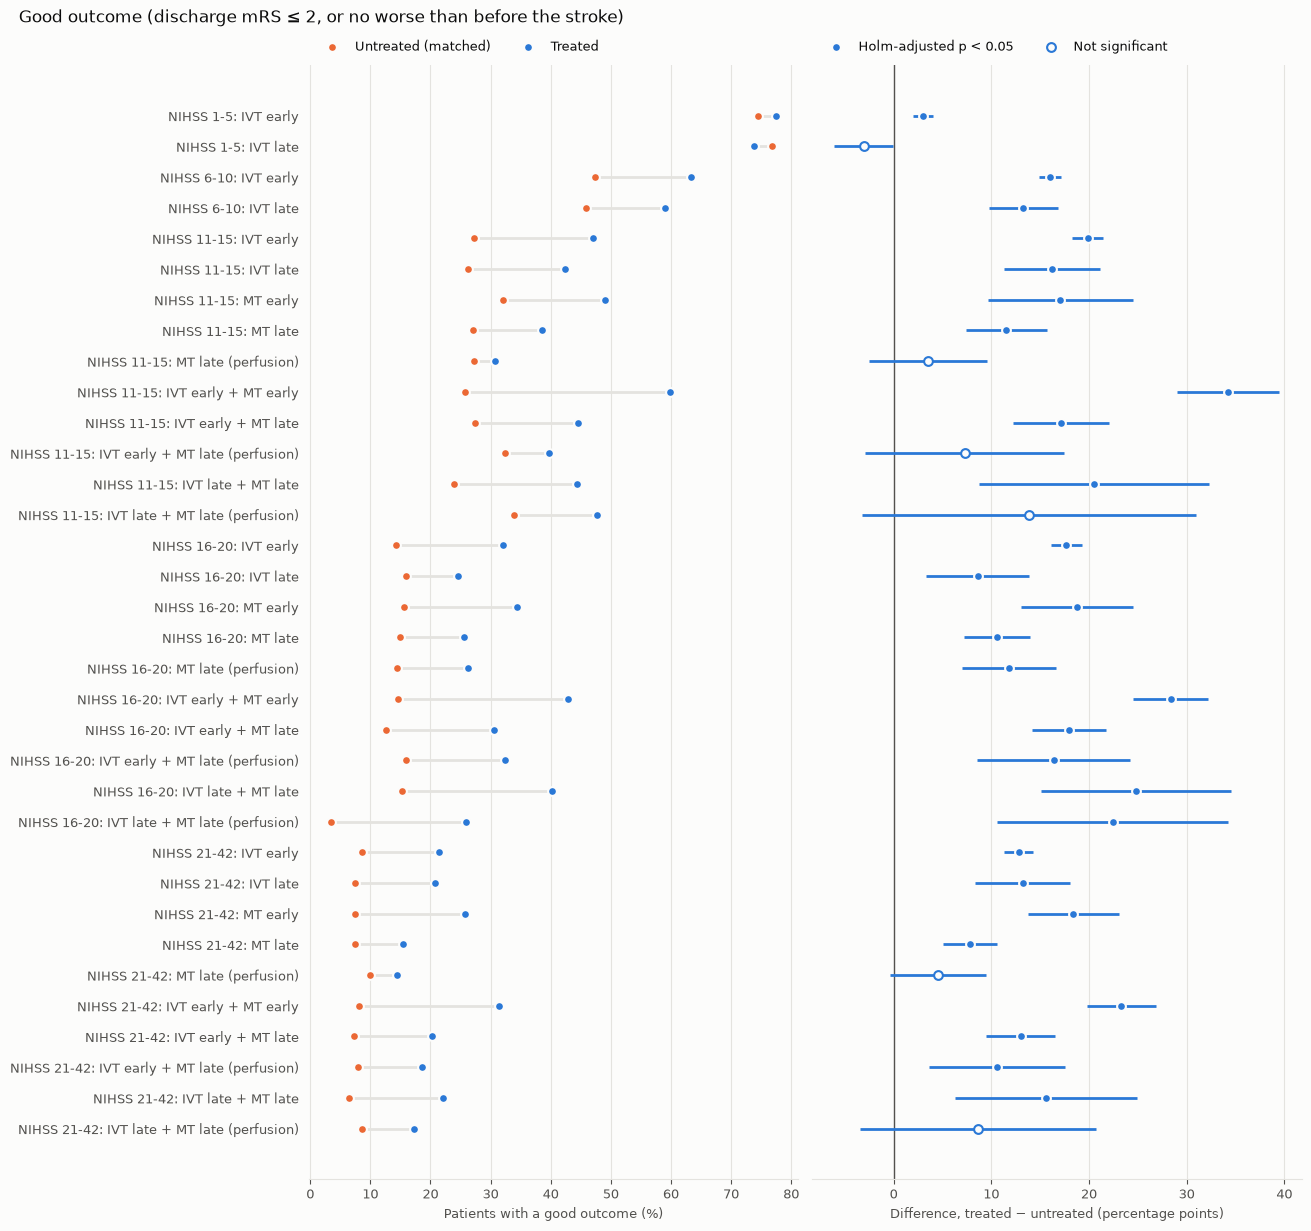

Saved table: ./output/all_ischaemic_stroke_target_trials_outcome_target_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_outcome_target_chart.png


,group_name,n_pairs,treated_events,treated_pct,untreated_events,untreated_pct,difference,ci_low,ci_high,matched_odds_ratio,or_ci_low,or_ci_high,test,p_value,p_value_holm
group_id,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,10034,77.458700,9647,74.471206,2.987494,1.975473,3.999516,1.188873,1.121035,1.260815,McNemar,8.23e-09,1.56e-07
2,NIHSS 1-5: IVT late,1440,1062,73.750000,1106,76.805556,-3.055556,-6.059247,-0.051864,0.834586,0.698378,0.997360,McNemar,0.0516,0.31
4,NIHSS 6-10: IVT early,13618,8632,63.386694,6447,47.341754,16.044941,14.918177,17.171704,2.017699,1.915976,2.124823,McNemar,4.01e-162,1.36e-160
5,NIHSS 6-10: IVT late,1478,873,59.066306,677,45.805142,13.261164,9.721426,16.800901,1.723247,1.483699,2.001471,McNemar,7.07e-13,1.84e-11
7,NIHSS 11-15: IVT early,6277,2952,47.028835,1705,27.162657,19.866178,18.258254,21.474102,2.509685,2.315232,2.720470,McNemar,1.77e-118,5.83e-117
8,NIHSS 11-15: IVT late,643,273,42.457232,169,26.283048,16.174184,11.263037,21.085330,2.209302,1.712483,2.850258,McNemar,5.65e-10,1.24e-08
10,NIHSS 11-15: MT early,281,138,49.110320,90,32.028470,17.081851,9.627730,24.535971,2.297297,1.561582,3.379634,McNemar,2.09e-05,0.000272
11,NIHSS 11-15: MT late,944,364,38.559322,255,27.012712,11.546610,7.441952,15.651269,1.741497,1.421789,2.133095,McNemar,7.45e-08,1.27e-06
12,NIHSS 11-15: MT late (perfusion),426,131,30.751174,116,27.230047,3.521127,-2.528323,9.570577,1.189873,0.882222,1.604810,McNemar,0.287,0.655


In [8]:
outcome_target_results = analyse_outcome(
    "outcome_target",
    "binary",
    title="Good outcome (discharge mRS ≤ 2, or no worse than before the stroke)",
    value_label="Patients with a good outcome (%)",
)

### Discharge disability (`discharge_disability`)

Continuous: modified Rankin Scale at discharge (0-6). Lower is better. As mRS is ordinal, the Wilcoxon signed-rank test is the primary test.

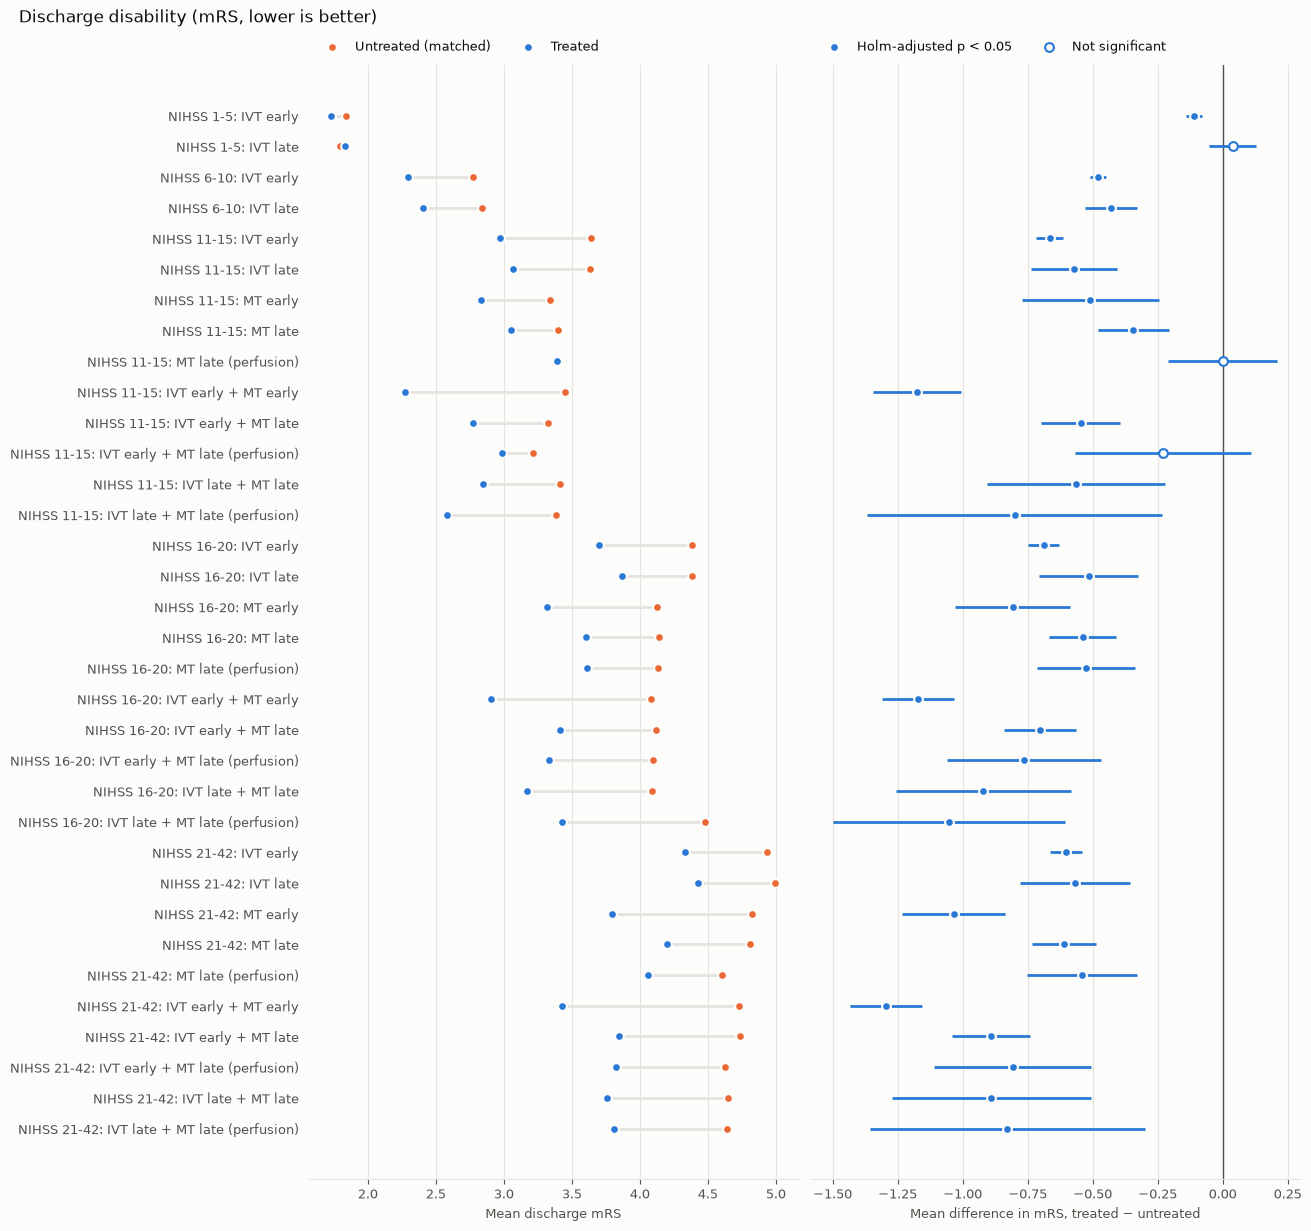

Saved table: ./output/all_ischaemic_stroke_target_trials_discharge_disability_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_discharge_disability_chart.png


,group_name,n_pairs,treated_mean,treated_sd,treated_median,treated_q1,treated_q3,untreated_mean,untreated_sd,untreated_median,untreated_q1,untreated_q3,difference,ci_low,ci_high,test,p_value,p_value_paired_t,p_value_holm
group_id,,,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,1.728810,1.370699,2.000000,1.000000,3.000000,1.838274,1.321136,2.000000,1.000000,3.000000,-0.109464,-0.139229,-0.079699,Wilcoxon signed-rank,1.81e-14,5.96e-13,3.81e-13
2,NIHSS 1-5: IVT late,1440,1.830556,1.430011,2.000000,1.000000,3.000000,1.792361,1.279256,2.000000,1.000000,3.000000,0.038194,-0.052083,0.128472,Wilcoxon signed-rank,0.574,0.407,1
4,NIHSS 6-10: IVT early,13618,2.293435,1.532096,2.000000,1.000000,3.000000,2.773094,1.470796,3.000000,2.000000,4.000000,-0.479659,-0.512000,-0.447319,Wilcoxon signed-rank,5.12e-177,2.47e-180,1.74e-175
5,NIHSS 6-10: IVT late,1478,2.407307,1.562683,2.000000,1.000000,3.000000,2.836265,1.427645,3.000000,2.000000,4.000000,-0.428958,-0.529016,-0.328900,Wilcoxon signed-rank,9.26e-17,9.58e-17,2.13e-15
7,NIHSS 11-15: IVT early,6277,2.973236,1.698681,3.000000,2.000000,4.000000,3.638522,1.532150,4.000000,3.000000,5.000000,-0.665286,-0.716770,-0.613802,Wilcoxon signed-rank,1.7e-127,7.04e-135,5.61e-126
8,NIHSS 11-15: IVT late,643,3.063764,1.658728,3.000000,2.000000,4.000000,3.636081,1.533044,4.000000,3.000000,5.000000,-0.572317,-0.736829,-0.407805,Wilcoxon signed-rank,2.46e-11,1.96e-11,4.43e-10
10,NIHSS 11-15: MT early,281,2.832740,1.699936,3.000000,2.000000,4.000000,3.341637,1.680989,3.000000,2.000000,4.000000,-0.508897,-0.772060,-0.245734,Wilcoxon signed-rank,8.44e-05,0.000173,0.000591
11,NIHSS 11-15: MT late,944,3.055085,1.576314,3.000000,2.000000,4.000000,3.399364,1.594809,3.000000,2.000000,4.000000,-0.344280,-0.480502,-0.208058,Wilcoxon signed-rank,3.63e-07,8.36e-07,5.08e-06
12,NIHSS 11-15: MT late (perfusion),426,3.394366,1.590965,4.000000,2.000000,4.000000,3.394366,1.559598,3.000000,2.000000,4.000000,0.000000,-0.210374,0.210374,Wilcoxon signed-rank,0.695,1,1


In [9]:
discharge_disability_results = analyse_outcome(
    "discharge_disability",
    "continuous",
    title="Discharge disability (mRS, lower is better)",
    value_label="Mean discharge mRS",
    diff_label="Mean difference in mRS, treated − untreated",
)

### Discharge destination (`discharge_destination`)

Categorical. Destinations recorded as "missing" are treated as missing data, so those pairs are dropped.

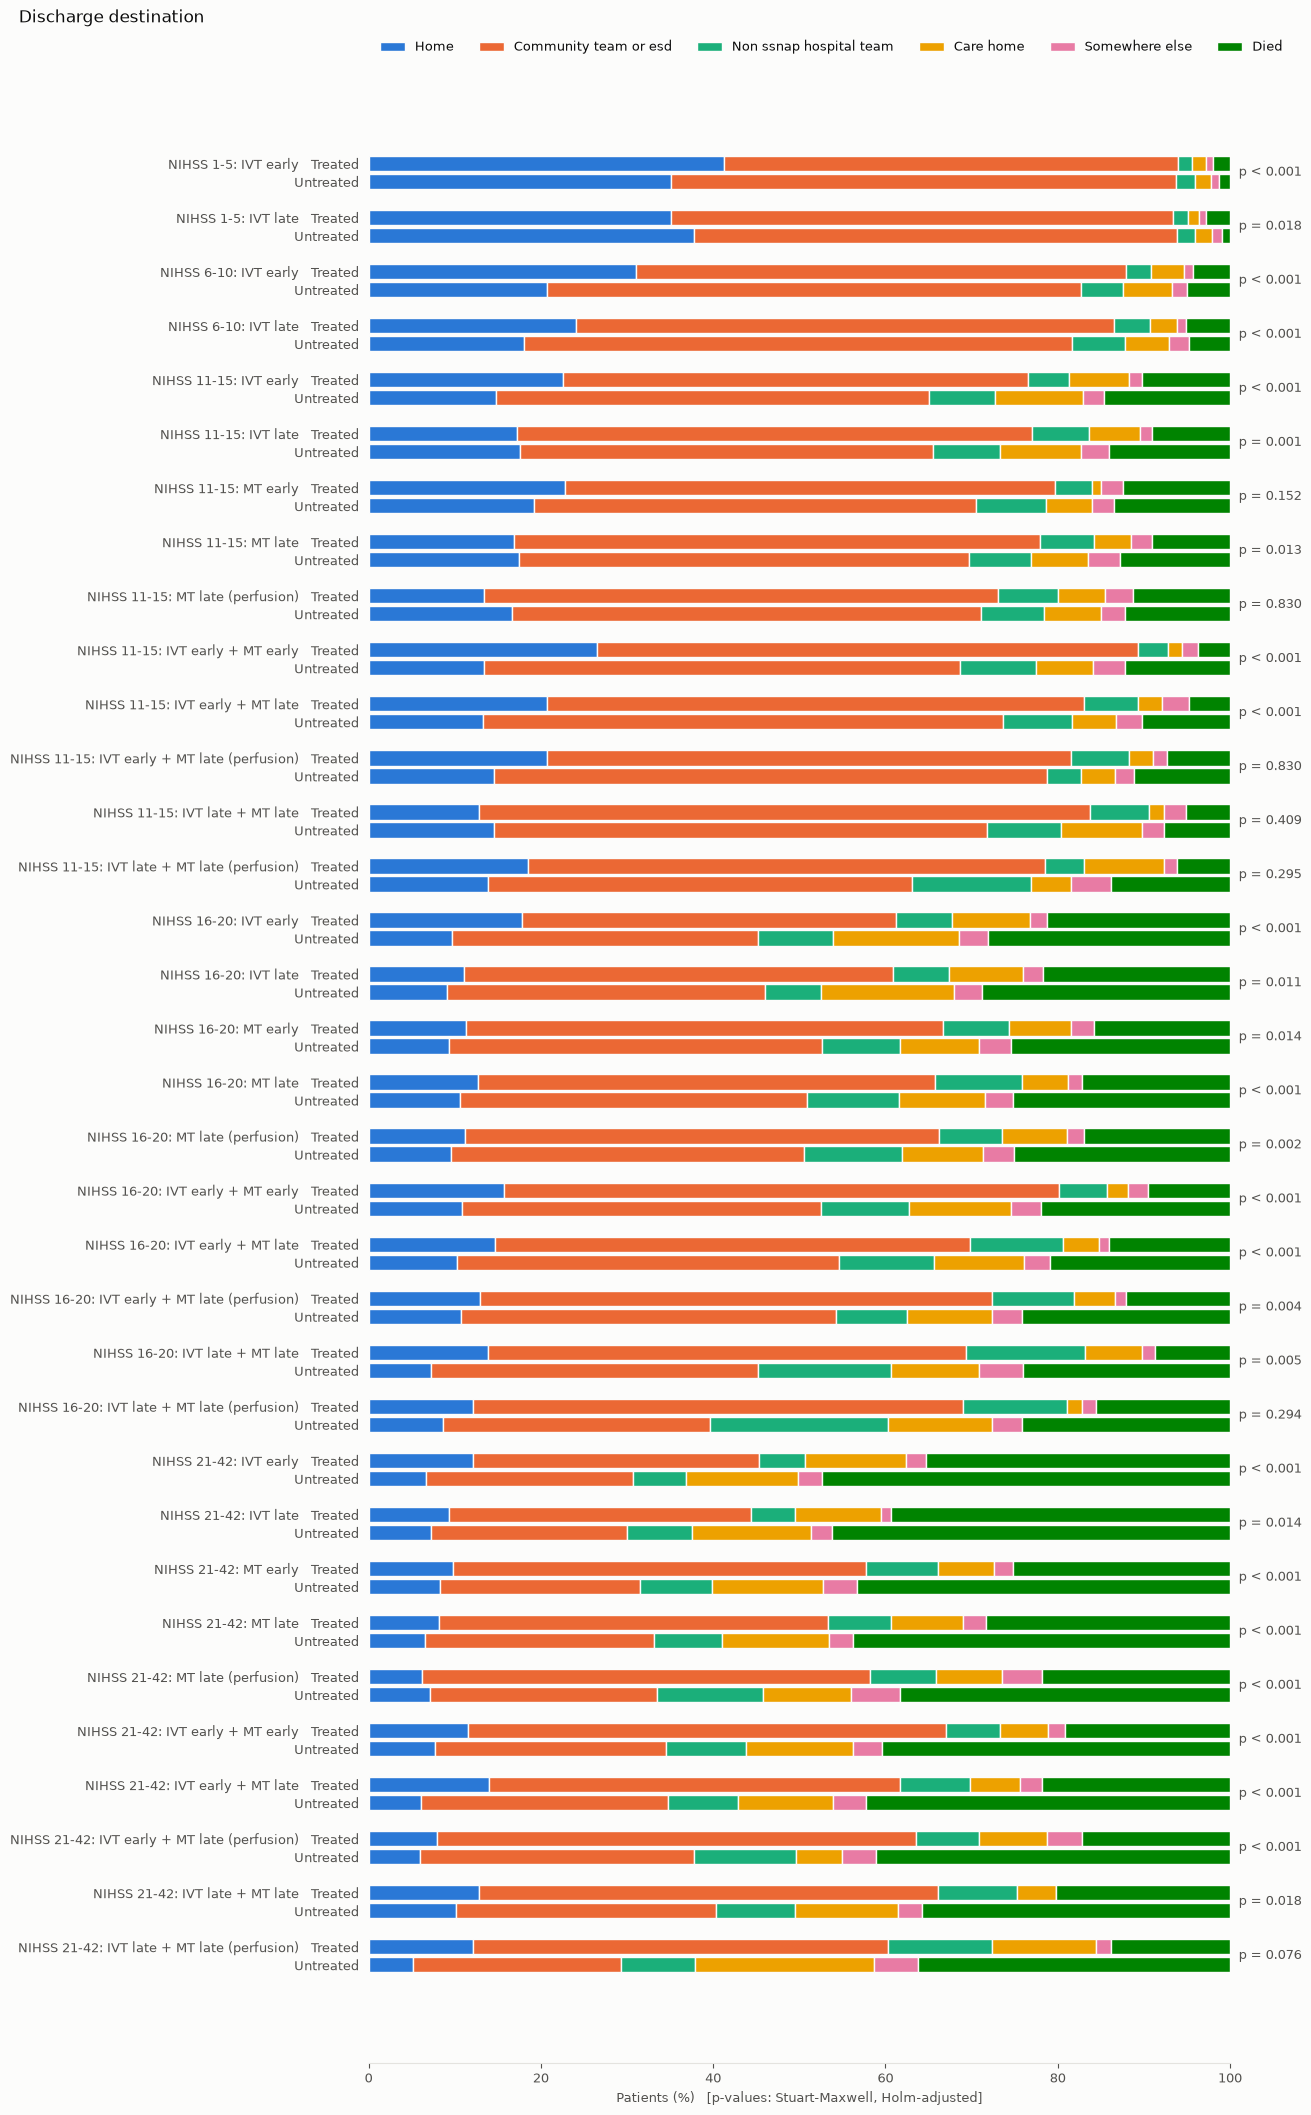

Saved table: ./output/all_ischaemic_stroke_target_trials_discharge_destination_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_discharge_destination_chart.png


,group_name,n_pairs,treated_pct_home,treated_pct_community_team_or_esd,treated_pct_non_ssnap_hospital_team,treated_pct_care_home,treated_pct_somewhere_else,treated_pct_died,untreated_pct_home,untreated_pct_community_team_or_esd,untreated_pct_non_ssnap_hospital_team,untreated_pct_care_home,untreated_pct_somewhere_else,untreated_pct_died,test,p_value,p_value_holm
group_id,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12952,41.260037,52.640519,1.683138,1.605930,0.802965,2.007412,35.137431,58.608709,2.177270,1.922483,0.918777,1.235330,Stuart-Maxwell,0,0
2,NIHSS 1-5: IVT late,1440,35.138889,58.263889,1.736111,1.250000,0.763889,2.847222,37.777778,56.041667,2.152778,1.944444,1.111111,0.972222,Stuart-Maxwell,0.0021,0.018
4,NIHSS 6-10: IVT early,13617,31.012705,56.884776,2.966880,3.818756,1.072189,4.244694,20.724095,61.974003,4.817508,5.728134,1.747815,5.008445,Stuart-Maxwell,0,0
5,NIHSS 6-10: IVT late,1478,24.086604,62.449256,4.127199,3.179973,1.082544,5.074425,17.997294,63.599459,6.156969,5.209743,2.232747,4.803789,Stuart-Maxwell,3.26e-06,6.53e-05
7,NIHSS 11-15: IVT early,6277,22.542616,54.038553,4.731560,6.945993,1.561255,10.180022,14.831926,50.183209,7.678827,10.259678,2.389677,14.656683,Stuart-Maxwell,0,0
8,NIHSS 11-15: IVT late,643,17.262830,59.720062,6.687403,5.909798,1.399689,9.020218,17.573872,47.900467,7.776050,9.486781,3.265941,13.996890,Stuart-Maxwell,7.48e-05,0.00127
10,NIHSS 11-15: MT early,281,22.775801,56.939502,4.270463,1.067616,2.491103,12.455516,19.217082,51.245552,8.185053,5.338078,2.491103,13.523132,Stuart-Maxwell,0.0254,0.152
11,NIHSS 11-15: MT late,944,16.843220,61.122881,6.250000,4.343220,2.330508,9.110169,17.478814,52.224576,7.203390,6.567797,3.707627,12.817797,Stuart-Maxwell,0.0011,0.0133
12,NIHSS 11-15: MT late (perfusion),426,13.380282,59.624413,7.042254,5.399061,3.286385,11.267606,16.666667,54.460094,7.276995,6.572770,2.816901,12.206573,Stuart-Maxwell,0.625,0.83


In [10]:
discharge_destination_results = analyse_outcome(
    "discharge_destination",
    "categorical",
    title="Discharge destination",
    category_order=[
        "home",
        "community_team_or_esd",
        "non_ssnap_hospital_team",
        "care_home",
        "somewhere_else",
        "died",
    ],
)

### Length of stay (`length_of_stay`)

Continuous, in days. Length of stay is right-skewed, so the Wilcoxon signed-rank test is the primary test. Patients who died in hospital are included.

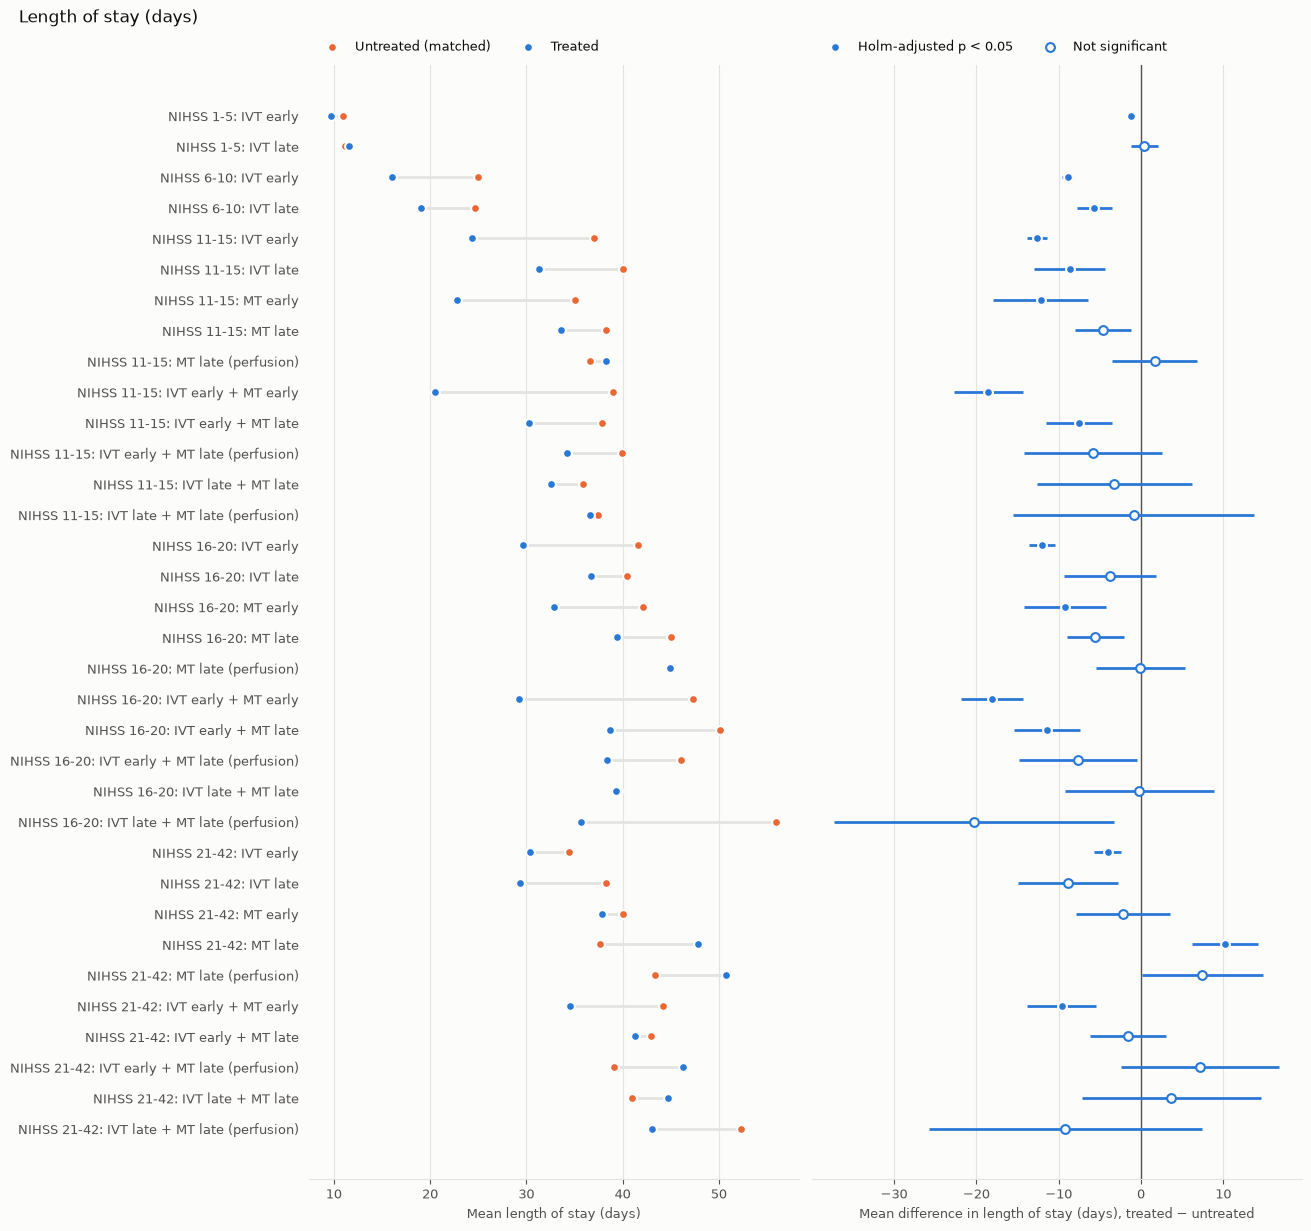

Saved table: ./output/all_ischaemic_stroke_target_trials_length_of_stay_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_length_of_stay_chart.png


,group_name,n_pairs,treated_mean,treated_sd,treated_median,treated_q1,treated_q3,untreated_mean,untreated_sd,untreated_median,untreated_q1,untreated_q3,difference,ci_low,ci_high,test,p_value,p_value_paired_t,p_value_holm
group_id,,,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12950,9.704093,19.329757,3.000000,2.000000,8.000000,10.902085,20.201254,4.000000,2.000000,10.000000,-1.197992,-1.672108,-0.723876,Wilcoxon signed-rank,1.69e-13,7.4e-07,4.89e-12
2,NIHSS 1-5: IVT late,1440,11.571528,22.986303,3.000000,2.000000,10.000000,11.166667,20.928250,3.000000,2.000000,10.000000,0.404861,-1.196265,2.005987,Wilcoxon signed-rank,0.492,0.62,1
4,NIHSS 6-10: IVT early,13616,16.077703,26.469084,5.000000,2.000000,18.000000,24.984504,31.552352,13.000000,5.000000,34.000000,-8.906801,-9.596155,-8.217447,Wilcoxon signed-rank,3.47e-238,2.57e-138,1.18e-236
5,NIHSS 6-10: IVT late,1478,19.006089,27.325602,7.000000,3.000000,24.000000,24.688769,31.680925,13.000000,4.000000,33.750000,-5.682679,-7.798075,-3.567284,Wilcoxon signed-rank,1.97e-11,1.57e-07,5.53e-10
7,NIHSS 11-15: IVT early,6274,24.400861,32.174274,11.000000,4.000000,34.000000,37.069015,37.783342,25.000000,9.000000,54.000000,-12.668154,-13.899192,-11.437116,Wilcoxon signed-rank,9.69e-113,9.74e-88,3.2e-111
8,NIHSS 11-15: IVT late,643,31.337481,38.407549,17.000000,5.000000,46.000000,40.020218,38.705026,28.000000,10.000000,58.500000,-8.682737,-12.950522,-4.414953,Wilcoxon signed-rank,1.18e-06,7.22e-05,2.83e-05
10,NIHSS 11-15: MT early,281,22.836299,29.972992,10.000000,5.000000,30.000000,35.028470,39.543727,21.000000,8.000000,53.000000,-12.192171,-17.941680,-6.442661,Wilcoxon signed-rank,3.06e-05,3.99e-05,0.000642
11,NIHSS 11-15: MT late,944,33.619703,37.412726,19.500000,6.000000,50.000000,38.268008,39.318360,25.000000,8.000000,58.000000,-4.648305,-8.060227,-1.236384,Wilcoxon signed-rank,0.0178,0.00763,0.267
12,NIHSS 11-15: MT late (perfusion),426,38.241784,39.734830,26.000000,8.000000,54.750000,36.582160,41.599820,23.000000,8.000000,54.750000,1.659624,-3.471129,6.790378,Wilcoxon signed-rank,0.291,0.525,1


In [11]:
length_of_stay_results = analyse_outcome(
    "length_of_stay",
    "continuous",
    title="Length of stay (days)",
    value_label="Mean length of stay (days)",
    diff_label="Mean difference in length of stay (days), treated − untreated",
)

### Death (`death`)

Binary: death in hospital. Lower is better.

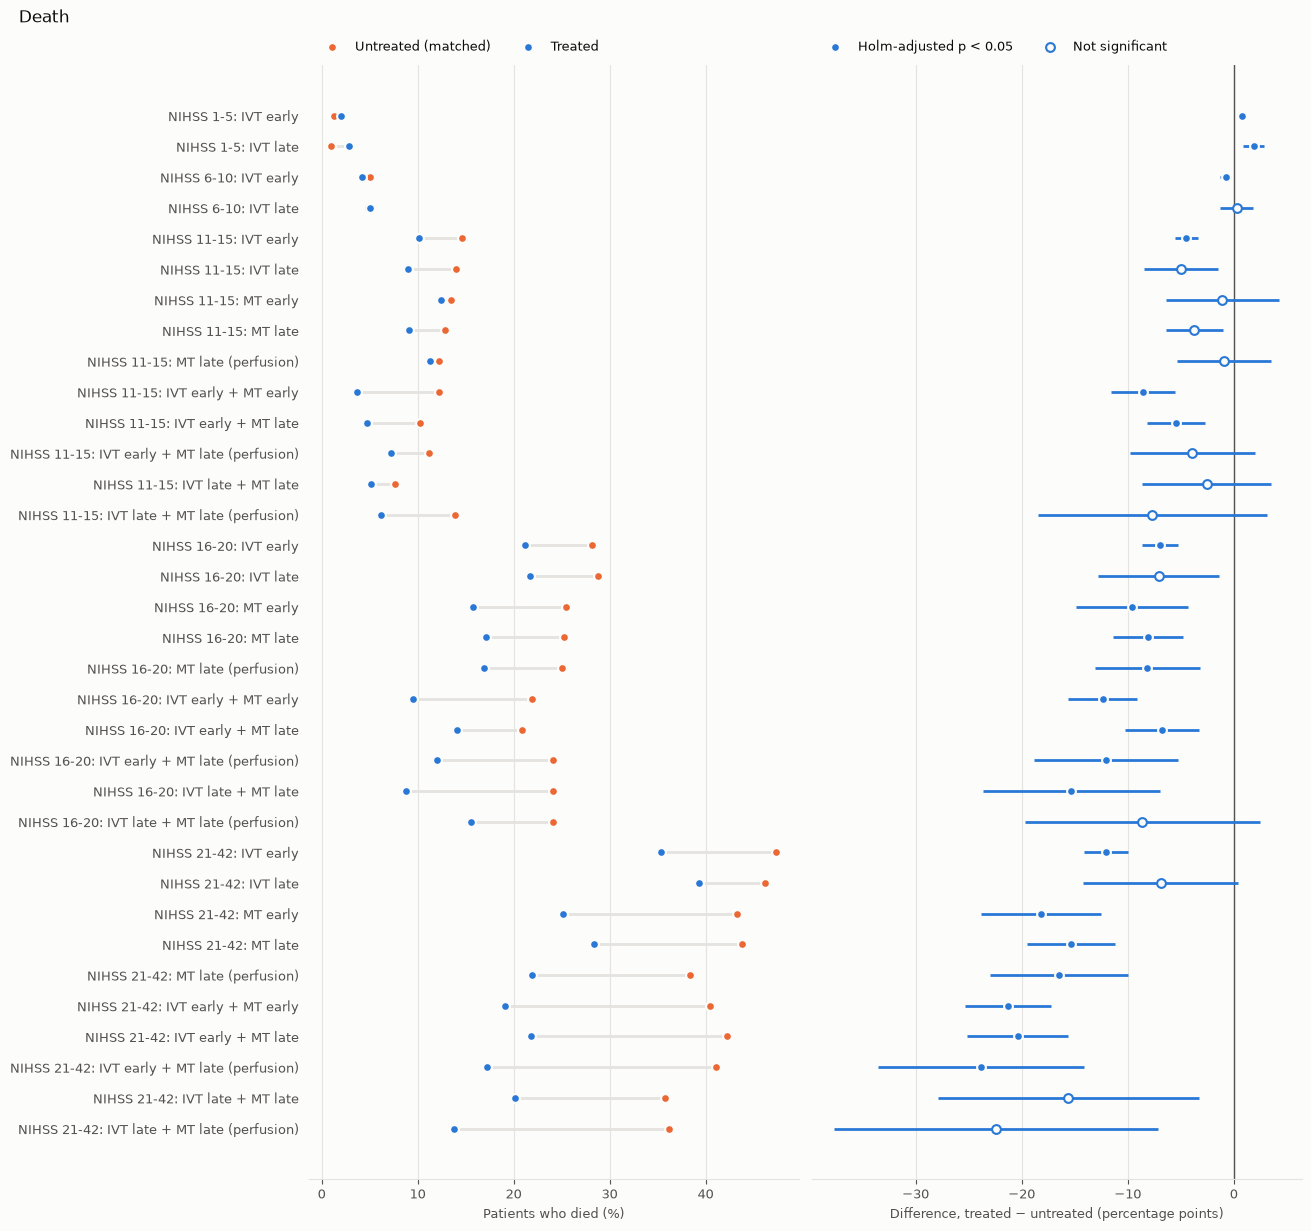

Saved table: ./output/all_ischaemic_stroke_target_trials_death_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_death_chart.png


,group_name,n_pairs,treated_events,treated_pct,untreated_events,untreated_pct,difference,ci_low,ci_high,matched_odds_ratio,or_ci_low,or_ci_high,test,p_value,p_value_holm
group_id,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,260,2.007102,160,1.235140,0.771962,0.465871,1.078054,1.645161,1.347451,2.008649,McNemar,1.01e-06,2.53e-05
2,NIHSS 1-5: IVT late,1440,41,2.847222,14,0.972222,1.875000,0.907473,2.842527,3.250000,1.701711,6.206988,McNemar,0.000272,0.00517
4,NIHSS 6-10: IVT early,13618,578,4.244382,683,5.015421,-0.771038,-1.266340,-0.275737,0.837209,0.746764,0.938608,McNemar,0.00252,0.0353
5,NIHSS 6-10: IVT late,1478,75,5.074425,71,4.803789,0.270636,-1.298916,1.840188,1.058824,0.760121,1.474906,McNemar,0.8,1
7,NIHSS 11-15: IVT early,6277,639,10.180022,920,14.656683,-4.476661,-5.578256,-3.375065,0.634590,0.566538,0.710817,McNemar,2.85e-15,9.1e-14
8,NIHSS 11-15: IVT late,643,58,9.020218,90,13.996890,-4.976672,-8.486932,-1.466412,0.614458,0.433553,0.870847,McNemar,0.00741,0.0963
10,NIHSS 11-15: MT early,281,35,12.455516,38,13.523132,-1.067616,-6.433385,4.298154,0.903226,0.541840,1.505641,McNemar,0.795,1
11,NIHSS 11-15: MT late,944,86,9.110169,121,12.817797,-3.707627,-6.429716,-0.985538,0.663462,0.489383,0.899461,McNemar,0.00974,0.117
12,NIHSS 11-15: MT late (perfusion),426,48,11.267606,52,12.206573,-0.938967,-5.356320,3.478385,0.916667,0.608909,1.379973,McNemar,0.754,1


In [12]:
death_results = analyse_outcome(
    "death",
    "binary",
    title="Death",
    value_label="Patients who died (%)",
)